In [1]:
# base modules
import math

# for manipulating data
import numpy as np
import pandas as pd

# for visualization
from matplotlib import pyplot as plt

# for Machine Learning
from sklearn import metrics
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

## Data preprocessing 

In [15]:
raw_data = pd.read_csv("hotel_bookings.csv", delimiter = ',', low_memory = False)
raw_data.shape
raw_data

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [ ]:
df_clean = raw_data.drop(columns = ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'company'])
df_clean = df_clean.drop_duplicates()

df_clean['agent'] = df_clean['agent'].fillna(0)
df_clean['children'] = df_clean['children'].fillna(0)
df_clean['country'] = df_clean['country'].fillna('Unknown')

months = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
          'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}

df_clean['arrival_month'] = df_clean['arrival_date_month'].map(months)

arrival_date = pd.to_datetime(dict(year = df_clean['arrival_date_year'],
                                   month = df_clean['arrival_month'],
                                   day = df_clean['arrival_date_day_of_month']))

df_clean['arrival_dayofweek'] = arrival_date.dt.dayofweek
df_clean = df_clean.drop(columns = ['arrival_date_month'])

text_columns = df_clean.select_dtypes(include = 'object').columns
for col in text_columns:
    df_clean[col] = df_clean[col].astype('category').cat.codes

print(raw_data.shape, '->', df_clean.shape)
print('missing values left:', df_clean.isnull().sum().sum())

(119390, 32) -> (86138, 29)
missing values left: 0


/var/folders/4g/drjfw3bs14l3mvctwcy3qv5m0000gn/T/ipykernel_55103/2566012375.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include = 'object').columns


In [17]:
y = df_clean['is_canceled']
df = df_clean.drop(columns = 'is_canceled')
df.shape

(86138, 28)

## Training, validation and test sets

In [18]:
# sort the bookings from the oldest to the newest arrival date
order = arrival_date.sort_values(kind = 'stable').index
df = df.loc[order]
y = y.loc[order]

df = df.drop(columns = 'arrival_date_year')

share_train = 0.6
share_valid = 0.2          # the rest (0.2) is the test set

n_total = len(df)
n_train = int(share_train * n_total)
n_valid = int(share_valid * n_total)

def split_vals(a, n):
    return a[:n].copy(), a[n:].copy()

X_train, X_rest = split_vals(df, n_train)
y_train, y_rest = split_vals(y, n_train)
X_valid, X_test = split_vals(X_rest, n_valid)
y_valid, y_test = split_vals(y_rest, n_valid)

for name, X_part, y_part in [('train', X_train, y_train), ('validation', X_valid, y_valid), ('test', X_test, y_test)]:
    dates = arrival_date.loc[X_part.index]
    print('{:<10} {:>6} bookings, arrivals from {} to {}, share cancelled = {:.3f}'.format(
        name, len(X_part), dates.min().date(), dates.max().date(), y_part.mean()))

train       51682 bookings, arrivals from 2015-07-01 to 2016-12-01, share cancelled = 0.247
validation  17227 bookings, arrivals from 2016-12-02 to 2017-05-03, share cancelled = 0.291
test        17229 bookings, arrivals from 2017-05-03 to 2017-08-31, share cancelled = 0.347


## Scaling the columns

In [19]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn the scaling on the training set, and apply it
X_valid_s = scaler.transform(X_valid)       # apply the same scaling to the validation set
X_test_s = scaler.transform(X_test)         # and to the test set

X_train_s.shape, X_valid_s.shape, X_test_s.shape


((51682, 27), (17227, 27), (17229, 27))

## Performance measures

In [ ]:
def base_classif_perf(y_true, y_pred, neg_label, pos_label) -> None:
   
   # Evaluate the performance of a binary classification model.

    print("Accuracy : {:.3f}".format(metrics.accuracy_score(y_true, y_pred)))
    print("Recall : {:.3f}".format(metrics.recall_score(y_true, y_pred, pos_label=pos_label)))
    print("Precision : {:.3f}".format(metrics.precision_score(y_true, y_pred, pos_label=pos_label)))
    print("F1 score : {:.3f}".format(metrics.f1_score(y_true, y_pred, pos_label=pos_label)))
    return

In [21]:
#always predict "not cancelled"
base_classif_perf(y_valid, np.zeros(len(y_valid), dtype = int), neg_label = 0, pos_label = 1)

Accuracy : 0.709
Recall : 0.000
Precision : 0.000
F1 score : 0.000


/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## First model: KNN with k = 5

In [22]:
knn = KNeighborsClassifier(n_neighbors = 5, n_jobs = -1)
knn.fit(X_train_s, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
print(knn.score(X_train_s[:10000], y_train[:10000]))   # accuracy on the training set
print(knn.score(X_valid_s, y_valid))                   # accuracy on the validation set

base_classif_perf(y_true = y_valid, y_pred = knn.predict(X_valid_s), neg_label = 0, pos_label = 1)

0.8919
0.7429035815870436
Accuracy : 0.743
Recall : 0.365
Precision : 0.595
F1 score : 0.453


In [24]:
proba_valid = knn.predict_proba(X_valid_s)[:, 1]   # probability of the class 1 (cancelled)

pd.DataFrame({'proba_cancelled': proba_valid[:5],
              'really_cancelled': y_valid.iloc[:5].values})

,proba_cancelled,really_cancelled
0,0.4,1
1,0.0,1
2,0.4,1
3,0.6,1
4,0.4,1


## Choosing k

In [26]:
from sklearn.model_selection import TimeSeriesSplit

param_grid = {'n_neighbors': [1, 5, 15, 31, 61, 101]}

grid_search = GridSearchCV(
    estimator = KNeighborsClassifier(n_jobs = -1),
    param_grid = param_grid,
    cv = TimeSeriesSplit(n_splits = 3),
    scoring = metrics.make_scorer(metrics.f1_score, pos_label = 1),
    verbose = 2,
)

grid_search.fit(X_train_s, y_train)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END ......................................n_neighbors=1; total time=   0.1s
[CV] END ......................................n_neighbors=1; total time=   0.1s
[CV] END ......................................n_neighbors=1; total time=   0.2s
[CV] END ......................................n_neighbors=5; total time=   0.1s
[CV] END ......................................n_neighbors=5; total time=   0.1s
[CV] END ......................................n_neighbors=5; total time=   0.2s
[CV] END .....................................n_neighbors=15; total time=   0.1s
[CV] END .....................................n_neighbors=15; total time=   0.1s
[CV] END .....................................n_neighbors=15; total time=   0.2s
[CV] END .....................................n_neighbors=31; total time=   0.1s
[CV] END .....................................n_neighbors=31; total time=   0.1s
[CV] END .....................................n_n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsCla...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=1)"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_

In [27]:
print("Best parameters:", grid_search.best_params_)
print("Best F1 score:", grid_search.best_score_)

Best parameters: {'n_neighbors': 5}
Best F1 score: 0.42816855090356604


In [28]:
report = pd.DataFrame(grid_search.cv_results_).sort_values(by = "mean_test_score", ascending = False)
report[['param_n_neighbors', 'mean_test_score']]

,param_n_neighbors,mean_test_score
1,5,0.428169
0,1,0.427517
2,15,0.423922
3,31,0.409132
4,61,0.389198
5,101,0.351087


In [29]:
best_knn = grid_search.best_estimator_
best_knn.fit(X_train_s, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [30]:
print(best_knn.score(X_train_s[:10000], y_train[:10000]))   # accuracy on (a part of) the training set
print(best_knn.score(X_valid_s, y_valid))                   # accuracy on the validation set

base_classif_perf(y_true = y_valid, y_pred = best_knn.predict(X_valid_s), neg_label = 0, pos_label = 1)

0.8919
0.7429035815870436
Accuracy : 0.743
Recall : 0.365
Precision : 0.595
F1 score : 0.453


In [31]:
proba_best = best_knn.predict_proba(X_valid_s)[:, 1]

pd.DataFrame({'proba_cancelled': proba_best[:5],
              'really_cancelled': y_valid.iloc[:5].values})

,proba_cancelled,really_cancelled
0,0.4,1
1,0.0,1
2,0.4,1
3,0.6,1
4,0.4,1


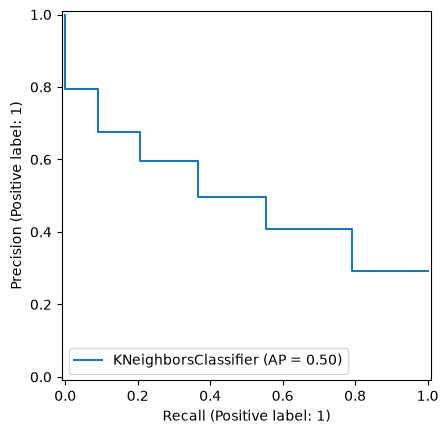

In [32]:
rec_prc_curve = metrics.PrecisionRecallDisplay.from_estimator(best_knn, X_valid_s, y_valid, pos_label = 1)

In [33]:
for threshold in [0.3, 0.4, 0.5]:
    print('threshold =', threshold)
    base_classif_perf(y_true = y_valid,
                      y_pred = (proba_best >= threshold).astype(int),
                      neg_label = 0, pos_label = 1)
    print()

threshold = 0.3
Accuracy : 0.707
Recall : 0.555
Precision : 0.496
F1 score : 0.524

threshold = 0.4
Accuracy : 0.707
Recall : 0.555
Precision : 0.496
F1 score : 0.524

threshold = 0.5
Accuracy : 0.743
Recall : 0.365
Precision : 0.595
F1 score : 0.453



## Test Set

In [34]:

base_classif_perf(y_true = y_test, y_pred = best_knn.predict(X_test_s), neg_label = 0, pos_label = 1)

Accuracy : 0.699
Recall : 0.421
Precision : 0.593
F1 score : 0.492
